# DL_04 — Technical Validation, Field Metrics, Error Maps and Ablation Studies

**Owner: Jashvita Lakshmi Omkaram**  
**Work package 4 of 5 — evaluation and validation**

## Objective

Evaluate the trained models on the locked family-held-out test set. Report field MAE, normalized RMSE, speed-magnitude errors, per-case errors and spatial error maps. Then perform input-channel ablations to test the value of wind direction and friction-velocity conditioning.

## Evaluation rules

- The test set is never used for training or early stopping.
- All metrics ignore building cells and non-finite CFD target cells.
- `field_component_MAE` is the mean absolute error pooled across both velocity components.
- `field_component_NRMSE` is component RMSE divided by the range of the true test-set component values. The denominator is stated explicitly.
- `pedestrian_speed_MAE_native_units` is computed after deriving speed as `sqrt(uped^2 + vped^2)`.
- Since the NetCDF component arrays do not contain units attributes, report component errors in stored/native field units unless the dataset authors confirm the units.
- Macro-averaged case metrics are also saved so that small and large grids can be compared with equal case weight.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# Locate the existing repository before importing the shared Phase 2 package.
current = Path.cwd().resolve()
candidates = [current, *current.parents]
ROOT = None
for candidate in candidates:
    if (candidate / "data" / "raw").is_dir() and (candidate / "Machine Learning Pipeline").is_dir():
        ROOT = candidate
        break
    if candidate.is_dir():
        for child in candidate.iterdir():
            if child.is_dir() and (child / "data" / "raw").is_dir() and (child / "Machine Learning Pipeline").is_dir():
                ROOT = child
                break
    if ROOT is not None:
        break
if ROOT is None:
    raise FileNotFoundError("Clone/open the existing T006 repository first; the Phase 2 folder must be added at its root.")

sys.path.insert(0, str(ROOT))
from dl_src.paths import get_project_paths
PATHS = get_project_paths(ROOT)
DL_RESULTS = PATHS["dl_results"]
FIELDS_DIR = PATHS["fields"]
FIGURES_DIR = PATHS["figures"]
MODELS_DIR = PATHS["models"]
PREDICTIONS_DIR = PATHS["predictions"]

print("Repository root:", ROOT)
print("Runtime outputs:", DL_RESULTS)


Repository root: /Users/suhaanigarg/Desktop/T006-urban-microclimate-modelling
Runtime outputs: /Users/suhaanigarg/Desktop/T006-urban-microclimate-modelling/dl_results


In [2]:
import torch
from torch.utils.data import DataLoader
from dl_src.data import FlowFieldDataset
from dl_src.models import load_unet_checkpoint, load_cnn_checkpoint, UNetVelocity
from dl_src.training import train_model
from dl_src.metrics import evaluate_model, save_selected_error_maps

from dl_src.training import get_torch_device
DEVICE = get_torch_device()
manifest = pd.read_csv(DL_RESULTS / "dl_case_metadata_manifest.csv")
split_manifest = pd.read_csv(DL_RESULTS / "dl_split_manifest.csv")
with open(DL_RESULTS / "normalization_stats.json", "r", encoding="utf-8") as file:
    normalization_stats = json.load(file)

test_dataset = FlowFieldDataset(manifest, split_manifest, FIELDS_DIR, "test", normalization_stats)
test_loader = DataLoader(test_dataset, batch_size=1, shuffle=False, num_workers=0)
print("Locked test cases:", len(test_dataset))
print("Test families:", sorted(split_manifest.loc[split_manifest["split"] == "test", "family_id"].unique()))

Locked test cases: 42
Test families: ['A0625', 'A1111', 'A4444']


## 1. Evaluate the U-Net on the test set

The model checkpoint is selected by validation loss in DL_03. This cell does not retrain the U-Net.

Pooled U-Net field metrics:


,aggregation,field_component_MAE,field_component_RMSE,field_component_NRMSE,pedestrian_speed_MAE_native_units,pedestrian_speed_RMSE_native_units,pedestrian_speed_NRMSE,valid_air_cells
0,all valid cells pooled,0.243839,0.341607,0.107148,0.243114,0.32045,0.180599,5157120


Per-case metrics:


,field_component_MAE,field_component_RMSE,field_component_NRMSE,pedestrian_speed_MAE_native_units,pedestrian_speed_RMSE_native_units,pedestrian_speed_NRMSE,valid_air_cells,simulation_id
0,0.322597,0.444287,0.168045,0.350278,0.432241,0.291411,229440,UA0625_d00
1,0.316937,0.406018,0.248792,0.303028,0.374252,0.292880,229440,UA0625_d45
2,0.223371,0.296923,0.159391,0.236123,0.295408,0.285856,121920,UA1111_d00
3,0.178717,0.247044,0.193481,0.180621,0.232701,0.236456,121920,UA1111_d45
4,0.096796,0.137872,0.197590,0.126550,0.157214,0.318228,18240,UA4444_d00


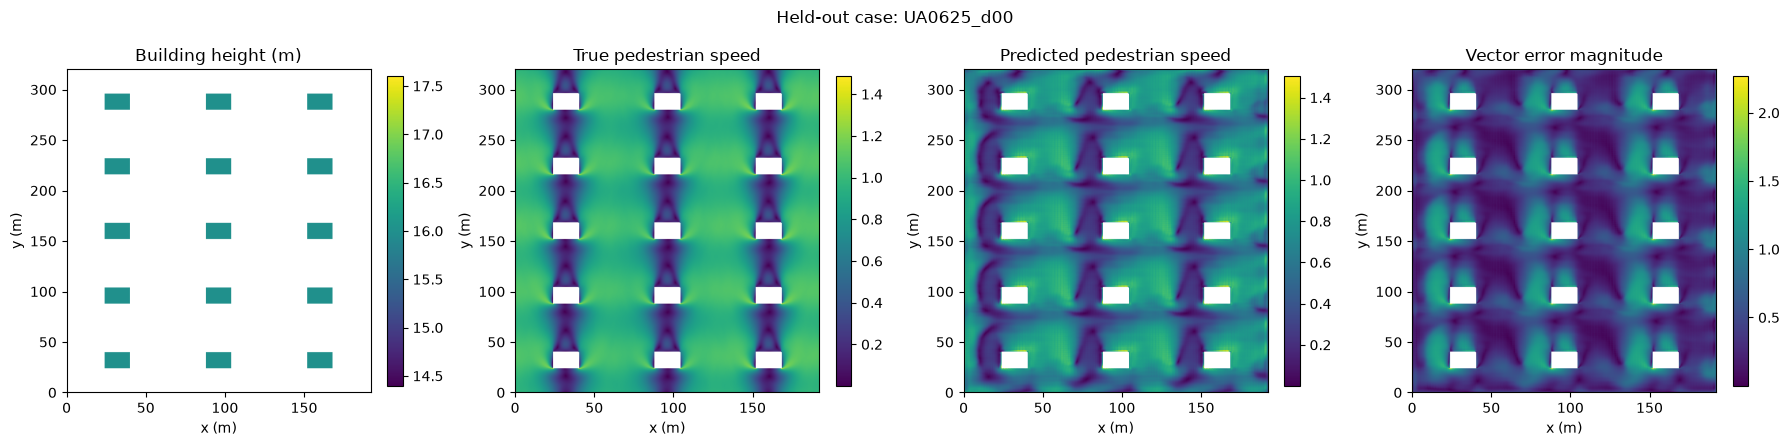

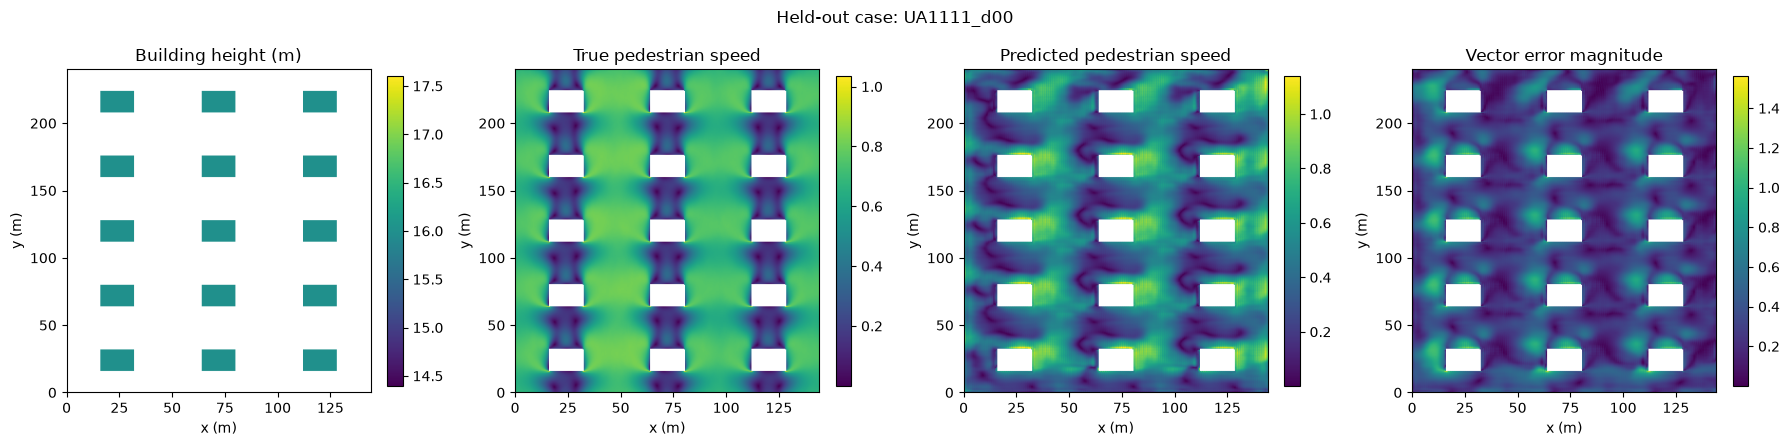

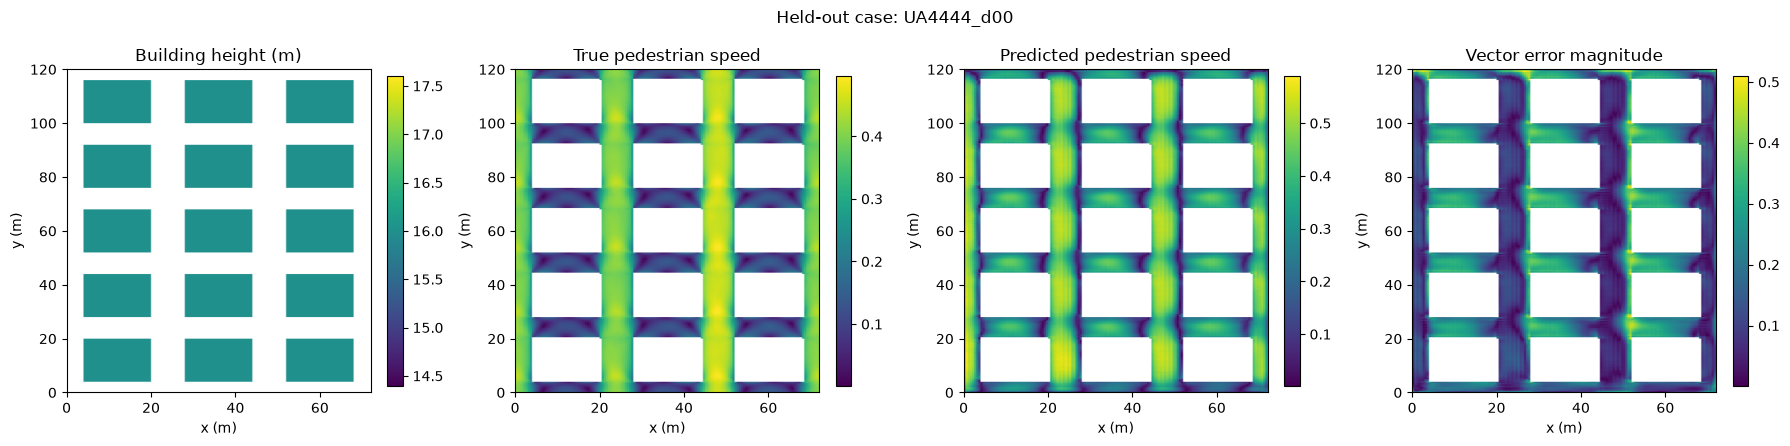

Saved example error maps for: ['UA0625_d00', 'UA1111_d00', 'UA4444_d00']


In [3]:
unet_model, unet_checkpoint_info = load_unet_checkpoint(MODELS_DIR / "unet_best.pt", DEVICE)
unet_case_metrics, unet_pooled_metrics, unet_predictions = evaluate_model(
    model=unet_model,
    data_loader=test_loader,
    normalization_stats=normalization_stats,
    device=DEVICE,
    model_name="unet",
    results_dir=DL_RESULTS,
    fields_dir=FIELDS_DIR,
)
print("Pooled U-Net field metrics:")
display(unet_pooled_metrics)
print("Per-case metrics:")
display(unet_case_metrics.head())
selected_error_cases = save_selected_error_maps(
    unet_predictions,
    FIGURES_DIR / "unet_error_maps",
    number_of_cases=3,
)
print("Saved example error maps for:", selected_error_cases)

## 2. Evaluate the compact CNN benchmark

This comparison uses the same held-out cases, target normalization, mask and metrics as the U-Net.

In [4]:
cnn_checkpoint_path = MODELS_DIR / "cnn_baseline_best.pt"
if cnn_checkpoint_path.exists():
    cnn_model, cnn_checkpoint_info = load_cnn_checkpoint(cnn_checkpoint_path, DEVICE)
    cnn_case_metrics, cnn_pooled_metrics, cnn_predictions = evaluate_model(
        model=cnn_model,
        data_loader=test_loader,
        normalization_stats=normalization_stats,
        device=DEVICE,
        model_name="cnn_baseline",
        results_dir=DL_RESULTS,
        fields_dir=FIELDS_DIR,
    )
    display(cnn_pooled_metrics)
else:
    cnn_case_metrics = None
    cnn_pooled_metrics = None
    print("CNN checkpoint not found. Run DL_03 with TRAIN_CNN_BASELINE=True for the architecture comparison.")

,aggregation,field_component_MAE,field_component_RMSE,field_component_NRMSE,pedestrian_speed_MAE_native_units,pedestrian_speed_RMSE_native_units,pedestrian_speed_NRMSE,valid_air_cells
0,all valid cells pooled,0.223752,0.283873,0.08904,0.243997,0.286997,0.161746,5157120


## 3. Input-channel ablation studies

Ablation experiments retrain the same U-Net family on the same train/validation/test split, changing only which input channels are supplied:

- **Full model:** building height, wind sine, wind cosine, friction velocity and domain mask.
- **Geometry-only:** building height and domain mask. This tests whether the wind/condition channels add useful information.
- **Without friction velocity:** building height, wind sine, wind cosine and domain mask. This tests the incremental value of the friction-velocity condition.

Ablations use a shorter, identical training budget so they remain practical. Treat them as controlled sensitivity experiments, not as a hyperparameter search. The full model's primary result remains the longer DL_03 training run.


Running: ablation_geometry_only | channels: [0, 4]
ablation_geometry_only | epoch 01/10 | train=0.659467 | validation=0.586579 | lr=1.00e-03
ablation_geometry_only | epoch 02/10 | train=0.557866 | validation=0.524498 | lr=1.00e-03
ablation_geometry_only | epoch 03/10 | train=0.527491 | validation=0.520856 | lr=1.00e-03
ablation_geometry_only | epoch 04/10 | train=0.498137 | validation=0.484868 | lr=1.00e-03
ablation_geometry_only | epoch 05/10 | train=0.475287 | validation=0.496536 | lr=1.00e-03
ablation_geometry_only | epoch 06/10 | train=0.444249 | validation=0.455532 | lr=1.00e-03
ablation_geometry_only | epoch 07/10 | train=0.428596 | validation=0.445675 | lr=1.00e-03
ablation_geometry_only | epoch 08/10 | train=0.403904 | validation=0.433548 | lr=1.00e-03
ablation_geometry_only | epoch 09/10 | train=0.399448 | validation=0.406768 | lr=1.00e-03
ablation_geometry_only | epoch 10/10 | train=0.377945 | validation=0.429940 | lr=1.00e-03


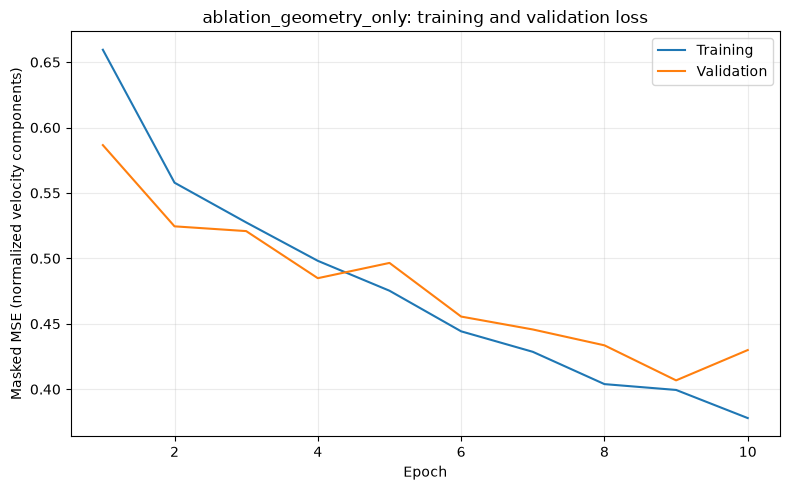

Best epoch: 9; best validation loss: 0.406768
Checkpoint: /Users/suhaanigarg/Desktop/T006-urban-microclimate-modelling/dl_results/models/ablation_geometry_only_best.pt
History: /Users/suhaanigarg/Desktop/T006-urban-microclimate-modelling/dl_results/ablation_geometry_only_training_history.csv

Running: ablation_without_u_tau | channels: [0, 1, 2, 4]
ablation_without_u_tau | epoch 01/10 | train=0.634309 | validation=0.531312 | lr=1.00e-03
ablation_without_u_tau | epoch 02/10 | train=0.514986 | validation=0.499565 | lr=1.00e-03
ablation_without_u_tau | epoch 03/10 | train=0.484279 | validation=0.471460 | lr=1.00e-03
ablation_without_u_tau | epoch 04/10 | train=0.445308 | validation=0.457596 | lr=1.00e-03
ablation_without_u_tau | epoch 05/10 | train=0.409603 | validation=0.415603 | lr=1.00e-03
ablation_without_u_tau | epoch 06/10 | train=0.371680 | validation=0.373431 | lr=1.00e-03
ablation_without_u_tau | epoch 07/10 | train=0.331155 | validation=0.377344 | lr=1.00e-03
ablation_without_u_

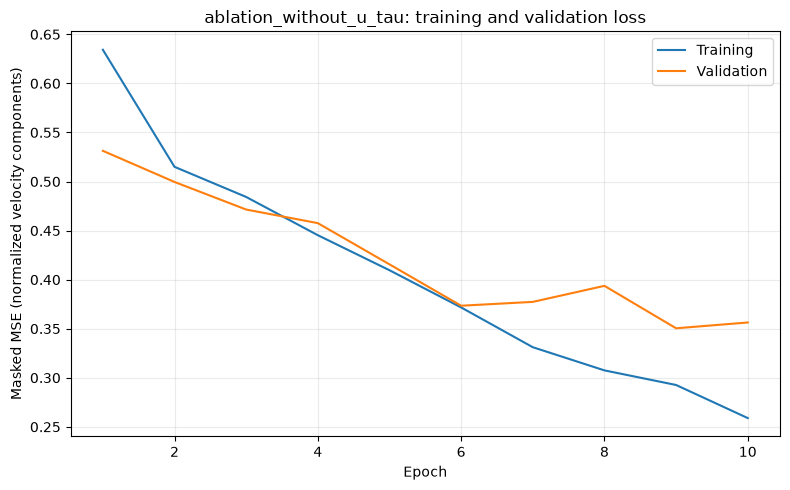

Best epoch: 9; best validation loss: 0.350446
Checkpoint: /Users/suhaanigarg/Desktop/T006-urban-microclimate-modelling/dl_results/models/ablation_without_u_tau_best.pt
History: /Users/suhaanigarg/Desktop/T006-urban-microclimate-modelling/dl_results/ablation_without_u_tau_training_history.csv


,aggregation,field_component_MAE,field_component_RMSE,field_component_NRMSE,pedestrian_speed_MAE_native_units,pedestrian_speed_RMSE_native_units,pedestrian_speed_NRMSE,valid_air_cells,model,input_channels
0,all valid cells pooled,0.281464,0.371574,0.116548,0.307794,0.374069,0.210818,5157120,ablation_geometry_only,"0,4"
1,all valid cells pooled,0.262293,0.357641,0.112178,0.295829,0.361991,0.204011,5157120,ablation_without_u_tau,"0,1,2,4"


In [5]:
ABLATION_EPOCHS = 10
ABLATION_PATIENCE = 4
ablation_definitions = {
    "ablation_geometry_only": [0, 4],
    "ablation_without_u_tau": [0, 1, 2, 4],
}

ablation_rows = []
for model_name, selected_channels in ablation_definitions.items():
    print("\nRunning:", model_name, "| channels:", selected_channels)
    train_ablation = FlowFieldDataset(
        manifest, split_manifest, FIELDS_DIR, "train", normalization_stats,
        channel_indices=selected_channels,
    )
    validation_ablation = FlowFieldDataset(
        manifest, split_manifest, FIELDS_DIR, "validation", normalization_stats,
        channel_indices=selected_channels,
    )
    test_ablation = FlowFieldDataset(
        manifest, split_manifest, FIELDS_DIR, "test", normalization_stats,
        channel_indices=selected_channels,
    )
    train_ablation_loader = DataLoader(train_ablation, batch_size=1, shuffle=True, num_workers=0)
    validation_ablation_loader = DataLoader(validation_ablation, batch_size=1, shuffle=False, num_workers=0)
    test_ablation_loader = DataLoader(test_ablation, batch_size=1, shuffle=False, num_workers=0)

    config = {
        "in_channels": len(selected_channels),
        "out_channels": 2,
        "base_channels": 8,
        "dropout": 0.10,
    }
    ablation_model = UNetVelocity(**config)
    ablation_model, history, checkpoint_path = train_model(
        model=ablation_model,
        train_loader=train_ablation_loader,
        validation_loader=validation_ablation_loader,
        device=DEVICE,
        output_dir=DL_RESULTS,
        model_name=model_name,
        epochs=ABLATION_EPOCHS,
        learning_rate=1e-3,
        weight_decay=1e-4,
        patience=ABLATION_PATIENCE,
        gradient_clip=1.0,
        model_config=config,
    )

    case_table, pooled_table, predictions = evaluate_model(
        model=ablation_model,
        data_loader=test_ablation_loader,
        normalization_stats=normalization_stats,
        device=DEVICE,
        model_name=model_name,
        results_dir=DL_RESULTS,
        fields_dir=FIELDS_DIR,
    )
    row = pooled_table.iloc[0].to_dict()
    row["model"] = model_name
    row["input_channels"] = ",".join(str(value) for value in selected_channels)
    ablation_rows.append(row)

ablation_table = pd.DataFrame(ablation_rows)
ablation_table.to_csv(DL_RESULTS / "dl_ablation_metrics.csv", index=False)
display(ablation_table)

## 4. Combine the model comparison table

Use the pooled-cell metrics for the headline field comparison and retain the macro case-level metrics as a second view. Do not choose a model using test metrics and then report the same test metrics as if the test set had remained untouched; the model architecture and training budget must be fixed before final submission.

In [6]:
comparison_rows = []
comparison_rows.append({"model": "U-Net", **unet_pooled_metrics.iloc[0].to_dict()})
if cnn_pooled_metrics is not None:
    comparison_rows.append({"model": "Compact CNN", **cnn_pooled_metrics.iloc[0].to_dict()})
for _, row in ablation_table.iterrows():
    comparison_rows.append({"model": row["model"], **row.to_dict()})

model_comparison = pd.DataFrame(comparison_rows)
model_comparison.to_csv(DL_RESULTS / "dl_model_comparison_and_ablations.csv", index=False)
display(model_comparison)

print("All metrics, per-case tables, prediction maps and checkpoints are generated under:", DL_RESULTS)

,model,aggregation,field_component_MAE,field_component_RMSE,field_component_NRMSE,pedestrian_speed_MAE_native_units,pedestrian_speed_RMSE_native_units,pedestrian_speed_NRMSE,valid_air_cells,input_channels
0,U-Net,all valid cells pooled,0.243839,0.341607,0.107148,0.243114,0.320450,0.180599,5157120,NaN
1,Compact CNN,all valid cells pooled,0.223752,0.283873,0.089040,0.243997,0.286997,0.161746,5157120,NaN
2,ablation_geometry_only,all valid cells pooled,0.281464,0.371574,0.116548,0.307794,0.374069,0.210818,5157120,"0,4"
3,ablation_without_u_tau,all valid cells pooled,0.262293,0.357641,0.112178,0.295829,0.361991,0.204011,5157120,"0,1,2,4"


All metrics, per-case tables, prediction maps and checkpoints are generated under: /Users/suhaanigarg/Desktop/T006-urban-microclimate-modelling/dl_results


## 5. Technical validation checklist

- [ ] Test families and layouts are disjoint from train and validation.
- [ ] Test predictions are cropped back to each original grid size.
- [ ] All field metrics use the valid-air mask.
- [ ] Field MAE and NRMSE definitions are stated in the report.
- [ ] At least three held-out spatial error maps are generated.
- [ ] U-Net is compared with the compact CNN baseline.
- [ ] Geometry-only and no-friction-velocity ablations are reported.
- [ ] Limitations about native field units, idealized geometry and small family count are explicit.

**Handoff:** Samarth uses the exact same locked split to add the Phase 1 XGBoost scalar prediction as a global conditioning channel in DL_05.